In [10]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from google.colab import files

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, DBSCAN
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.metrics import silhouette_score

sns.set_theme(style="whitegrid")


In [11]:
uploaded = files.upload()
filename = next(iter(uploaded))

if filename.endswith((".xlsx", ".xls")):
    df = pd.read_excel(filename)
else:
    df = pd.read_csv(filename, encoding="ISO-8859-1")

df.columns = df.columns.str.strip()

print(df.shape)
display(df.head())
print(df.isnull().sum())


Saving archive (2).zip to archive (2) (1).zip
(541909, 8)


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,12/1/2010 8:26,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,12/1/2010 8:26,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,12/1/2010 8:26,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,12/1/2010 8:26,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,12/1/2010 8:26,3.39,17850.0,United Kingdom


InvoiceNo           0
StockCode           0
Description      1454
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     135080
Country             0
dtype: int64


In [12]:
df = df.dropna(subset=["CustomerID"])
df = df.drop_duplicates()

df["InvoiceDate"] = pd.to_datetime(df["InvoiceDate"])
df["CustomerID"] = df["CustomerID"].astype(int)

df = df[~df["InvoiceNo"].astype(str).str.startswith("C")]

df = df[(df["Quantity"] > 0) & (df["UnitPrice"] > 0)]

df["Revenue"] = df["Quantity"] * df["UnitPrice"]

print("Rows after cleaning:", len(df))
print("Customers:", df["CustomerID"].nunique())


Rows after cleaning: 392692
Customers: 4338


            Quantity                    InvoiceDate      UnitPrice  \
count  392692.000000                         392692  392692.000000   
mean       13.119702  2011-07-10 19:13:07.771892480       3.125914   
min         1.000000            2010-12-01 08:26:00       0.001000   
25%         2.000000            2011-04-07 11:12:00       1.250000   
50%         6.000000            2011-07-31 12:02:00       1.950000   
75%        12.000000            2011-10-20 12:53:00       3.750000   
max     80995.000000            2011-12-09 12:50:00    8142.750000   
std       180.492832                            NaN      22.241836   

          CustomerID        Revenue  
count  392692.000000  392692.000000  
mean    15287.843865      22.631500  
min     12346.000000       0.001000  
25%     13955.000000       4.950000  
50%     15150.000000      12.450000  
75%     16791.000000      19.800000  
max     18287.000000  168469.600000  
std      1713.539549     311.099224  


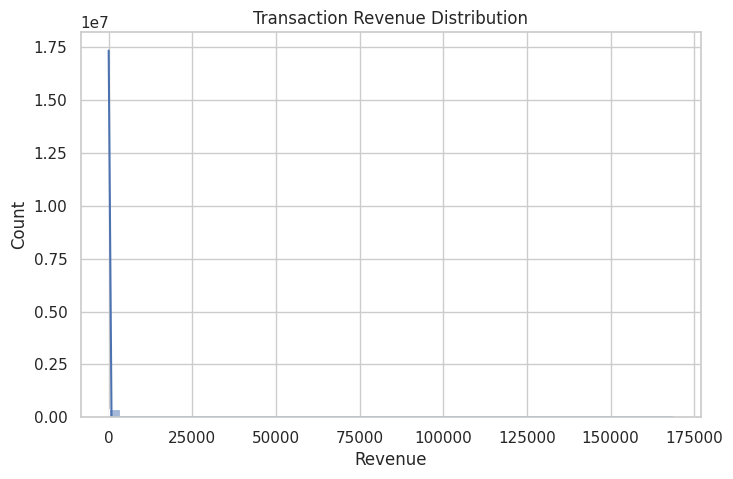

In [13]:
print(df.describe())

plt.figure(figsize=(8, 5))
sns.histplot(df["Revenue"], bins=50, kde=True)
plt.title("Transaction Revenue Distribution")
plt.show()


In [14]:
analysis_date = df["InvoiceDate"].max().normalize() + pd.Timedelta(days=1)

rfm = df.groupby("CustomerID").agg(
    Recency=("InvoiceDate", lambda x: (analysis_date - x.max().normalize()).days),
    Frequency=("InvoiceNo", "nunique"),
    Monetary=("Revenue", "sum")
)

print("RFM Dataset:")
display(rfm.head())
print(rfm.describe())


RFM Dataset:


,Recency,Frequency,Monetary
CustomerID,,,
12346,326,1,77183.60
12347,3,7,4310.00
12348,76,4,1797.24
12349,19,1,1757.55
12350,311,1,334.40


           Recency    Frequency       Monetary
count  4338.000000  4338.000000    4338.000000
mean     93.059474     4.272015    2048.688081
std     100.012264     7.697998    8985.230220
min       1.000000     1.000000       3.750000
25%      18.000000     1.000000     306.482500
50%      51.000000     2.000000     668.570000
75%     142.750000     5.000000    1660.597500
max     374.000000   209.000000  280206.020000


In [15]:
rfm_log = np.log1p(rfm)


In [16]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(rfm_log)


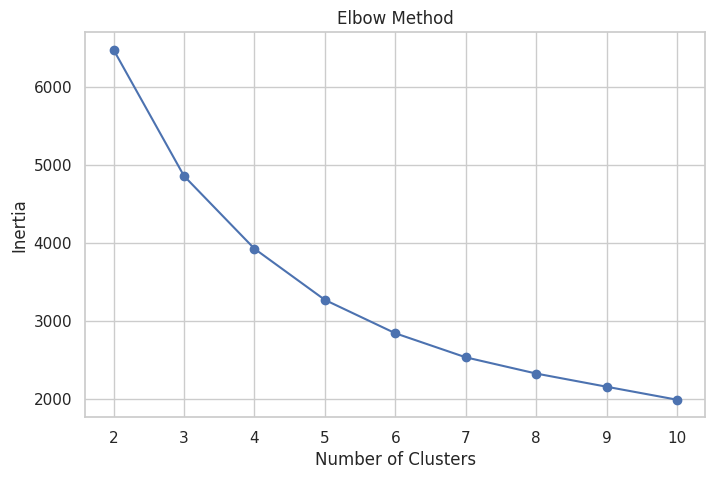

In [17]:
inertias = []
k_values = range(2, 11)

for k in k_values:
    model = KMeans(n_clusters=k, random_state=42, n_init=10)
    model.fit(X_scaled)
    inertias.append(model.inertia_)

plt.figure(figsize=(8, 5))
plt.plot(list(k_values), inertias, marker="o")
plt.title("Elbow Method")
plt.xlabel("Number of Clusters")
plt.ylabel("Inertia")
plt.show()


,K,Silhouette Score
0,2,0.432509
1,3,0.336288
2,4,0.332902
3,5,0.318078
4,6,0.312873
5,7,0.310296
6,8,0.302062
7,9,0.296021
8,10,0.277079


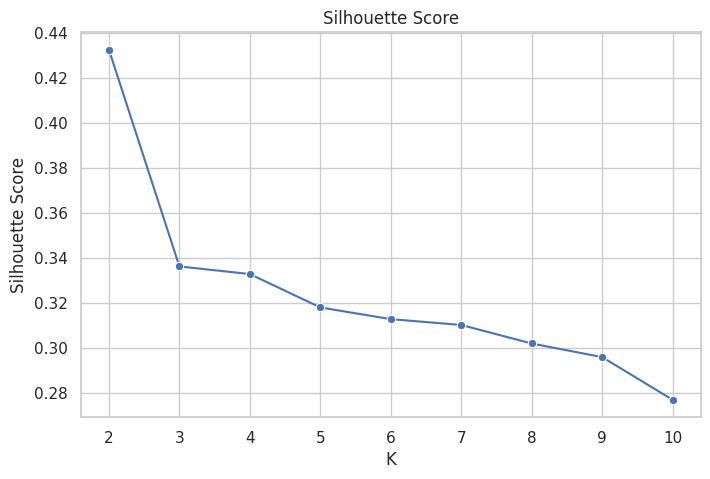

In [9]:
silhouette_results = []

for k in range(2, 11):
    model = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = model.fit_predict(X_scaled)
    score = silhouette_score(
        X_scaled, labels,
        sample_size=min(5000, len(X_scaled)),
        random_state=42
    )
    silhouette_results.append((k, score))

silhouette_df = pd.DataFrame(silhouette_results, columns=["K", "Silhouette Score"])
display(silhouette_df)

plt.figure(figsize=(8, 5))
sns.lineplot(data=silhouette_df, x="K", y="Silhouette Score", marker="o")
plt.title("Silhouette Score")
plt.show()


In [18]:
kmeans = KMeans(n_clusters=4, random_state=42, n_init=10)
rfm["KMeans_Cluster"] = kmeans.fit_predict(X_scaled)

print("K-Means Cluster Counts:")
print(rfm["KMeans_Cluster"].value_counts())


K-Means Cluster Counts:
KMeans_Cluster
2    1549
1    1174
0     897
3     718
Name: count, dtype: int64


Explained Variance:
[0.75119928 0.18739887]
Total Variance: 0.9385981492664273


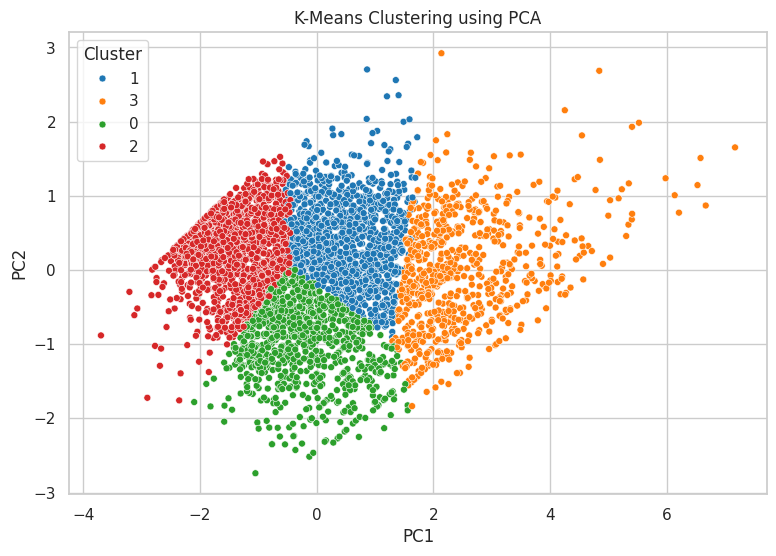

In [19]:
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

print("Explained Variance:")
print(pca.explained_variance_ratio_)
print("Total Variance:", pca.explained_variance_ratio_.sum())

pca_df = pd.DataFrame(X_pca, columns=["PC1", "PC2"], index=rfm.index)
pca_df["Cluster"] = rfm["KMeans_Cluster"].astype(str)

plt.figure(figsize=(9, 6))
sns.scatterplot(data=pca_df, x="PC1", y="PC2", hue="Cluster", palette="tab10", s=25)
plt.title("K-Means Clustering using PCA")
plt.show()


In [20]:
dbscan = DBSCAN(eps=0.7, min_samples=10)
dbscan_labels = dbscan.fit_predict(X_scaled)

rfm["DBSCAN_Cluster"] = dbscan_labels

print("DBSCAN Cluster Counts:")
print(rfm["DBSCAN_Cluster"].value_counts())
print("Number of Clusters:", len(set(dbscan_labels) - {-1}))
print("Noise Points:", (dbscan_labels == -1).sum())


DBSCAN Cluster Counts:
DBSCAN_Cluster
 0    4298
-1      40
Name: count, dtype: int64
Number of Clusters: 1
Noise Points: 40


In [21]:
dbscan_results = []

for eps in [0.3, 0.5, 0.7, 1.0, 1.2]:
    for min_samples in [5, 10, 15]:
        labels = DBSCAN(eps=eps, min_samples=min_samples).fit_predict(X_scaled)
        clusters = len(set(labels) - {-1})
        noise_percent = np.mean(labels == -1) * 100
        dbscan_results.append({
            "eps": eps,
            "min_samples": min_samples,
            "clusters": clusters,
            "noise_percent": round(noise_percent, 2)
        })

dbscan_results_df = pd.DataFrame(dbscan_results)
display(dbscan_results_df)


,eps,min_samples,clusters,noise_percent
0,0.3,5,6,5.62
1,0.3,10,4,9.45
2,0.3,15,5,14.73
3,0.5,5,2,1.43
4,0.5,10,2,1.82
5,0.5,15,2,2.42
6,0.7,5,2,0.58
7,0.7,10,1,0.92
8,0.7,15,1,0.97
9,1.0,5,1,0.23


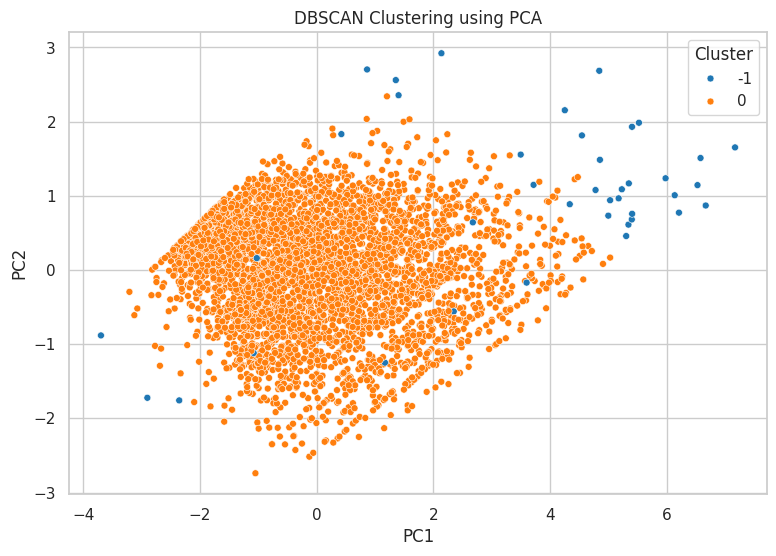

In [22]:
pca_dbscan_df = pca_df.copy()
pca_dbscan_df["Cluster"] = rfm["DBSCAN_Cluster"].astype(str)

plt.figure(figsize=(9, 6))
sns.scatterplot(data=pca_dbscan_df, x="PC1", y="PC2", hue="Cluster", palette="tab10", s=25)
plt.title("DBSCAN Clustering using PCA")
plt.show()


In [23]:
def evaluate_clusters(X, labels):
    labels = np.asarray(labels)
    mask = labels != -1

    X_eval = X[mask]
    labels_eval = labels[mask]

    n_clusters = len(np.unique(labels_eval))

    if n_clusters < 2 or n_clusters >= len(labels_eval):
        score = np.nan
    else:
        score = silhouette_score(
            X_eval, labels_eval,
            sample_size=min(5000, len(X_eval)),
            random_state=42
        )

    return {
        "Clusters": n_clusters,
        "Noise Percentage": np.mean(labels == -1) * 100,
        "Silhouette Score": score
    }


print("K-Means:", evaluate_clusters(X_scaled, rfm["KMeans_Cluster"]))
print("DBSCAN:", evaluate_clusters(X_scaled, rfm["DBSCAN_Cluster"]))


K-Means: {'Clusters': 4, 'Noise Percentage': np.float64(0.0), 'Silhouette Score': np.float64(0.33290207168555713)}
DBSCAN: {'Clusters': 1, 'Noise Percentage': np.float64(0.9220839096357769), 'Silhouette Score': nan}


In [24]:
sample_size = min(5000, len(rfm))
rng = np.random.default_rng(42)
sample_positions = np.sort(rng.choice(len(rfm), size=sample_size, replace=False))

X_tsne_input = X_scaled[sample_positions]
sample_index = rfm.index[sample_positions]

perplexity = min(30, max(5, (sample_size - 1) // 3))

tsne = TSNE(
    n_components=2,
    perplexity=perplexity,
    init="pca",
    learning_rate="auto",
    random_state=42
)

X_tsne = tsne.fit_transform(X_tsne_input)

tsne_df = pd.DataFrame(X_tsne, columns=["TSNE1", "TSNE2"], index=sample_index)
tsne_df["KMeans_Cluster"] = rfm.loc[sample_index, "KMeans_Cluster"].astype(str)
tsne_df["DBSCAN_Cluster"] = rfm.loc[sample_index, "DBSCAN_Cluster"].astype(str)


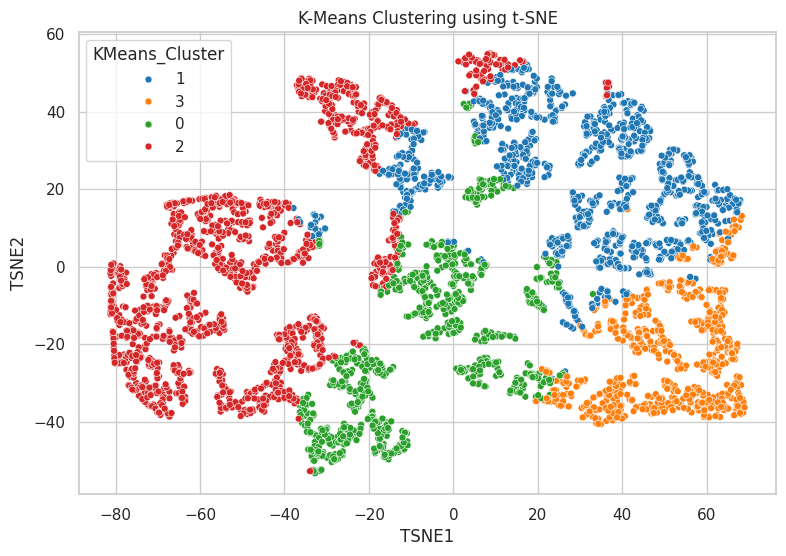

In [25]:
plt.figure(figsize=(9, 6))
sns.scatterplot(data=tsne_df, x="TSNE1", y="TSNE2", hue="KMeans_Cluster", palette="tab10", s=25)
plt.title("K-Means Clustering using t-SNE")
plt.show()


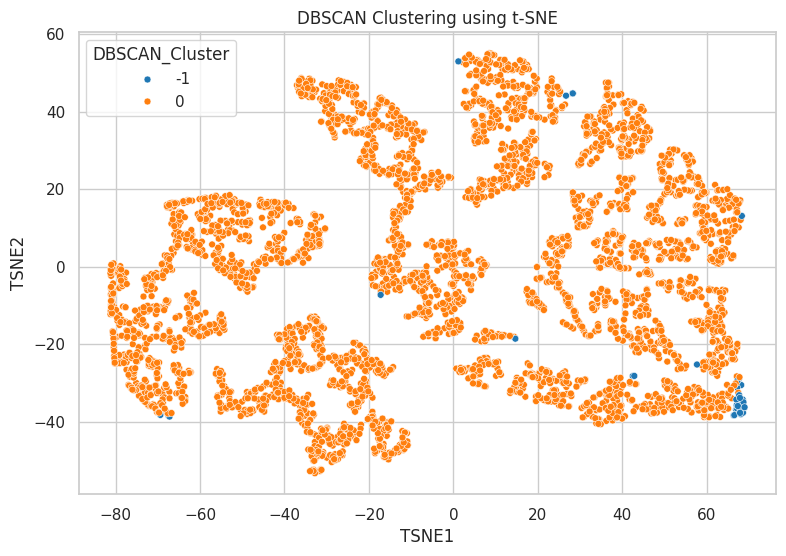

In [26]:
plt.figure(figsize=(9, 6))
sns.scatterplot(data=tsne_df, x="TSNE1", y="TSNE2", hue="DBSCAN_Cluster", palette="tab10", s=25)
plt.title("DBSCAN Clustering using t-SNE")
plt.show()


In [27]:
kmeans_profile = rfm.groupby("KMeans_Cluster").agg(
    Customers=("Recency", "size"),
    Avg_Recency=("Recency", "mean"),
    Avg_Frequency=("Frequency", "mean"),
    Avg_Monetary=("Monetary", "mean"),
    Median_Recency=("Recency", "median"),
    Median_Frequency=("Frequency", "median"),
    Median_Monetary=("Monetary", "median")
).round(2)

kmeans_profile["Customer_Percent"] = (100 * kmeans_profile["Customers"] / len(rfm)).round(2)
display(kmeans_profile)


,Customers,Avg_Recency,Avg_Frequency,Avg_Monetary,Median_Recency,Median_Frequency,Median_Monetary,Customer_Percent
KMeans_Cluster,,,,,,,,
0,897,22.79,1.92,486.06,20.0,2.0,414.20,20.68
1,1174,65.29,4.19,1822.98,52.0,4.0,1355.04,27.06
2,1549,192.27,1.35,360.55,187.0,1.0,303.16,35.71
3,718,12.21,13.64,8011.89,9.0,10.0,3687.77,16.55


In [28]:
dbscan_profile = rfm.groupby("DBSCAN_Cluster").agg(
    Customers=("Recency", "size"),
    Avg_Recency=("Recency", "mean"),
    Avg_Frequency=("Frequency", "mean"),
    Avg_Monetary=("Monetary", "mean"),
    Median_Recency=("Recency", "median"),
    Median_Frequency=("Frequency", "median"),
    Median_Monetary=("Monetary", "median")
).round(2)

dbscan_profile["Customer_Percent"] = (100 * dbscan_profile["Customers"] / len(rfm)).round(2)
display(dbscan_profile)


,Customers,Avg_Recency,Avg_Frequency,Avg_Monetary,Median_Recency,Median_Frequency,Median_Monetary,Customer_Percent
DBSCAN_Cluster,,,,,,,,
-1,40,53.75,45.72,61558.44,5.0,41.5,43295.13,0.92
0,4298,93.43,3.89,1494.85,52.0,2.0,660.66,99.08


In [29]:
overall_medians = rfm[["Recency", "Frequency", "Monetary"]].median()


def draft_persona(row):
    recent = row["Median_Recency"] <= overall_medians["Recency"]
    frequent = row["Median_Frequency"] >= overall_medians["Frequency"]
    high_value = row["Median_Monetary"] >= overall_medians["Monetary"]

    if recent and frequent and high_value:
        return ("Loyal High-Value Customers",
                "VIP rewards, early access and loyalty benefits")
    elif not recent and (frequent or high_value):
        return ("At-Risk Valuable Customers",
                "Personalized win-back campaigns")
    elif recent and not frequent:
        return ("Recent Promising Customers",
                "Second-purchase incentives and recommendations")
    else:
        return ("Low-Engagement Customers",
                "Low-cost email campaigns and relevant bundles")


persona_rows = []

for cluster_id, row in kmeans_profile.iterrows():
    name, action = draft_persona(row)
    persona_rows.append({
        "Cluster": cluster_id,
        "Customer Persona": name,
        "Marketing Strategy": action
    })

persona_table = pd.DataFrame(persona_rows)
display(persona_table)


,Cluster,Customer Persona,Marketing Strategy
0,0,Low-Engagement Customers,Low-cost email campaigns and relevant bundles
1,1,At-Risk Valuable Customers,Personalized win-back campaigns
2,2,Low-Engagement Customers,Low-cost email campaigns and relevant bundles
3,3,Loyal High-Value Customers,"VIP rewards, early access and loyalty benefits"


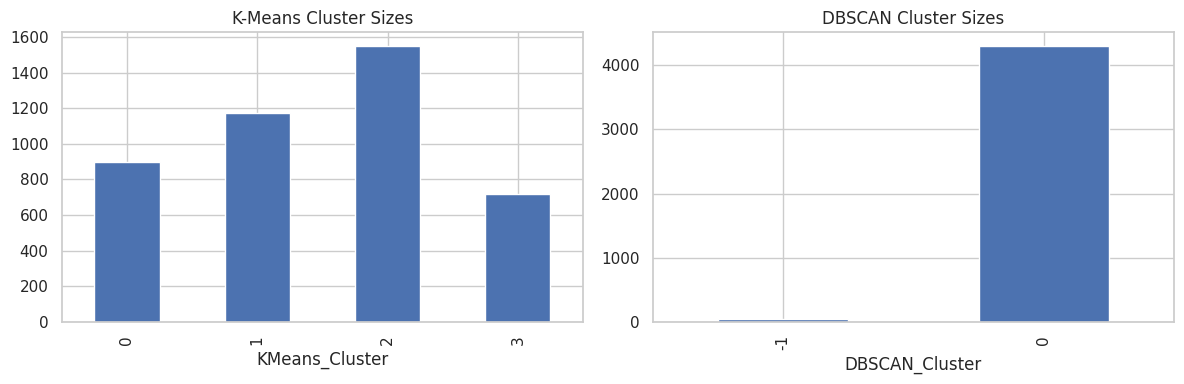

In [30]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

rfm["KMeans_Cluster"].value_counts().sort_index().plot(
    kind="bar", ax=axes[0], title="K-Means Cluster Sizes")

rfm["DBSCAN_Cluster"].value_counts().sort_index().plot(
    kind="bar", ax=axes[1], title="DBSCAN Cluster Sizes")

plt.tight_layout()
plt.show()


In [31]:
rfm.to_csv("customer_segments.csv")
kmeans_profile.to_csv("kmeans_cluster_profile.csv")
dbscan_profile.to_csv("dbscan_cluster_profile.csv")
persona_table.to_csv("marketing_personas.csv", index=False)
pca_df.to_csv("pca_visualization.csv")
tsne_df.to_csv("tsne_visualization.csv")

print("All project files exported successfully.")


All project files exported successfully.


In [32]:
files.download("customer_segments.csv")
files.download("kmeans_cluster_profile.csv")
files.download("dbscan_cluster_profile.csv")
files.download("marketing_personas.csv")
files.download("pca_visualization.csv")
files.download("tsne_visualization.csv")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

... (2 outputs left out)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>